# What Drives Medical Insurance Charges?

**Author:** XIE AN (MC652723)
**Project:** Data Science Portfolio — CISC7204, University of Macau

## Research question

Which customer attributes are associated with annual medical insurance charges,
and how does smoking status change the relationship between body mass index (BMI)
and cost?

## Dataset

The file `data/medical_insurance_raw.csv` is the teaching dataset distributed by
IBM Skills Network for the *Data Analysis with Python* (DA0101EN) course. It holds
2,772 anonymised policyholder records with seven fields: age, gender, BMI, number
of children, smoker status, US region and annual charges in USD. The file is
redistributed here unchanged, for educational and non-commercial use; it contains
no personally identifiable information.

The raw file has no header row and uses `?` to mark missing values, so the first
step is to load and clean it.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Resolve paths so the notebook runs from the repository root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

## 1. Load the data

In [2]:
columns = ["age", "gender", "bmi", "no_of_children", "smoker", "region", "charges"]
df = pd.read_csv(DATA_DIR / "medical_insurance_raw.csv", header=None, names=columns)
df.head()

,age,gender,bmi,no_of_children,smoker,region,charges
0,19,1,27.900,0,1,3,16884.92400
1,18,2,33.770,1,0,4,1725.55230
2,28,2,33.000,3,0,4,4449.46200
3,33,2,22.705,0,0,1,21984.47061
4,32,2,28.880,0,0,1,3866.85520


## 2. Data quality check

The `?` markers are read as text, so every column has to be coerced to a numeric
type before any statistics are computed.

In [3]:
df = df.replace("?", pd.NA)
df = df.apply(pd.to_numeric, errors="coerce")
df.dtypes.to_frame("dtype").T

,age,gender,bmi,no_of_children,smoker,region,charges
dtype,float64,int64,float64,int64,float64,int64,float64


In [4]:
missing = df.isna().sum()
missing[missing > 0].to_frame("missing_values")

,missing_values
age,4
smoker,7


## 3. Clean the data

Only eleven records (0.4%) are affected: four missing ages and seven missing
smoking flags. Because both fields are central to the analysis and the loss is
negligible, those rows are dropped rather than imputed.

In [5]:
df = df.dropna(subset=["age", "bmi", "smoker", "charges"]).copy()
df["smoker"] = df["smoker"].astype(int)
df["no_of_children"] = df["no_of_children"].astype(int)
df["region"] = df["region"].astype(int)

df.to_csv(DATA_DIR / "medical_insurance_clean.csv", index=False)
print(f"{len(df)} rows kept, {df.shape[1]} columns")

2761 rows kept, 7 columns


In [6]:
df[["age", "bmi", "no_of_children", "charges"]].describe().round(2)

,age,bmi,no_of_children,charges
count,2761.00,2761.00,2761.00,2761.00
mean,39.12,30.72,1.10,13274.76
std,14.09,6.13,1.21,12158.76
min,18.00,15.96,0.00,1121.87
25%,26.00,26.22,0.00,4718.20
50%,39.00,30.50,1.00,9377.90
75%,51.00,34.80,2.00,16577.78
max,64.00,53.13,5.00,63770.43


Charges are strongly right-skewed: the mean (\$13,275) sits well above the median
(\$9,378), which is typical of cost data and matters for the modelling choices later.

## 4. Smoking status and BMI

The first question is whether BMI affects cost equally for smokers and non-smokers.
A scatter plot with a separate fitted line per group answers it directly.

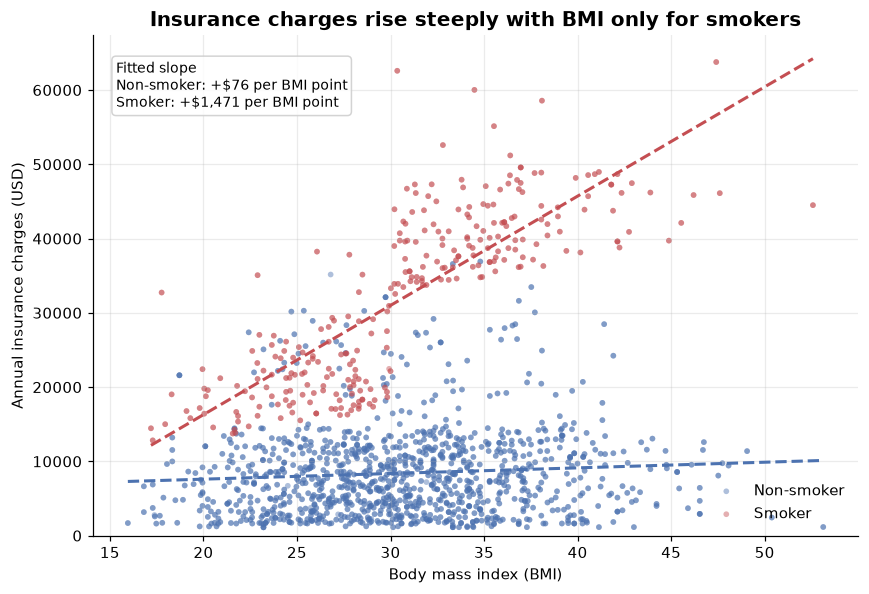

In [7]:
colors = {0: "#4C72B0", 1: "#C44E52"}
labels = {0: "Non-smoker", 1: "Smoker"}

slopes = {}
fig, ax = plt.subplots(figsize=(8, 5.5))

for status in [0, 1]:
    subset = df[df["smoker"] == status]
    ax.scatter(
        subset["bmi"], subset["charges"],
        s=14, alpha=0.45, color=colors[status], label=labels[status], edgecolors="none",
    )
    slope, intercept = np.polyfit(subset["bmi"], subset["charges"], 1)
    bmi_range = np.linspace(subset["bmi"].min(), subset["bmi"].max(), 50)
    ax.plot(bmi_range, slope * bmi_range + intercept, color=colors[status], lw=2, ls="--")
    slopes[status] = slope

ax.set_title("Insurance charges rise steeply with BMI only for smokers")
ax.set_xlabel("Body mass index (BMI)")
ax.set_ylabel("Annual insurance charges (USD)")
ax.set_ylim(0, None)
ax.text(
    0.03, 0.95,
    f"Fitted slope\nNon-smoker: +${slopes[0]:,.0f} per BMI point\n"
    f"Smoker: +${slopes[1]:,.0f} per BMI point",
    transform=ax.transAxes, va="top", fontsize=9,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="#cccccc"),
)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(FIG_DIR / "charges_vs_bmi_by_smoker.png", bbox_inches="tight")
plt.show()

The two groups behave completely differently. Two smokers with the same weight can
face bills that differ by tens of thousands of dollars, while for non-smokers BMI
barely moves the bill. The correlation between BMI and charges is 0.81 among
smokers but only 0.08 among non-smokers, so any model that adds BMI without an
interaction term will understate the risk carried by smokers.

## 5. Age and smoking

Age is the second structural factor. Median charges are compared across age bands
within each smoking group, which keeps the comparison robust to the skewed tail.

In [8]:
bins = [17, 29, 39, 49, 59, 64]
band_labels = ["18-29", "30-39", "40-49", "50-59", "60-64"]
df["age_band"] = pd.cut(df["age"], bins=bins, labels=band_labels)

median_by_age = (
    df.groupby(["age_band", "smoker"], observed=True)["charges"]
      .median()
      .unstack()
      .rename(columns={0: "Non-smoker", 1: "Smoker"})
)
median_by_age.round(0)

smoker,Non-smoker,Smoker
age_band,,
18-29,2709.0,33733.0
30-39,5425.0,36837.0
40-49,8252.0,37830.0
50-59,11363.0,42580.0
60-64,13827.0,46659.0


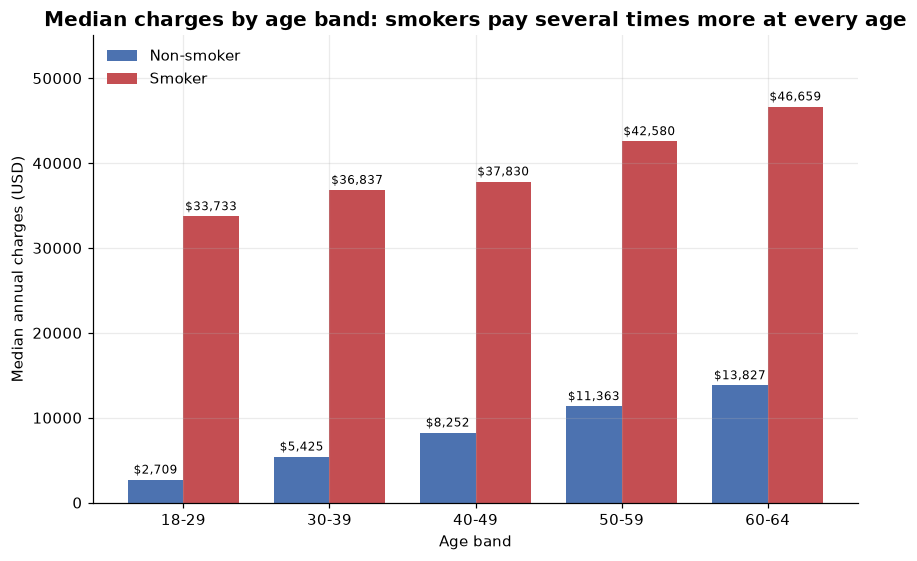

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.2))
x = np.arange(len(median_by_age))
width = 0.38

for offset, status in zip([-width / 2, width / 2], ["Non-smoker", "Smoker"]):
    bars = ax.bar(
        x + offset, median_by_age[status], width,
        color="#4C72B0" if status == "Non-smoker" else "#C44E52",
        label=status,
    )
    ax.bar_label(bars, labels=[f"${v:,.0f}" for v in median_by_age[status]], fontsize=8, padding=2)

ax.set_xticks(x, [str(label) for label in median_by_age.index])
ax.set_title("Median charges by age band: smokers pay several times more at every age")
ax.set_xlabel("Age band")
ax.set_ylabel("Median annual charges (USD)")
ax.set_ylim(0, median_by_age.to_numpy().max() * 1.18)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "median_charges_by_age_and_smoker.png", bbox_inches="tight")
plt.show()

Three patterns are visible:

- Smokers pay roughly **4.7 times** the median of non-smokers (\$34,780 vs \$7,345).
- The absolute gap also widens with age, from about \$31,000 in the 18-29 band to
  about \$32,800 at 60-64, while the relative gap narrows from roughly 12-fold to
  3.4-fold because non-smokers' costs climb faster with age.
- Age matters for everyone, but the smoking penalty dominates at every age band.

## 6. Do region and children matter?

Two further fields are available. Their group medians are checked to see whether
they deserve a place in the model or can be treated as controls.

In [10]:
region_summary = df.groupby("region")["charges"].median().to_frame("median_charges")
children_summary = df.groupby("no_of_children")["charges"].median().to_frame("median_charges")

pd.concat(
    [region_summary.assign(feature="region", value=region_summary.index),
     children_summary.assign(feature="no_of_children", value=children_summary.index)],
    ignore_index=True,
).pivot(index="value", columns="feature", values="median_charges").round(0)

feature,no_of_children,region
value,,
0,9850.0,NaN
1,8428.0,9194.0
2,9305.0,10072.0
3,10560.0,8791.0
4,11034.0,9141.0
5,8597.0,NaN


Neither field shows a monotone relationship. Median charges across the four regions
span only about \$1,300, and the number of children moves the median erratically.
Both are kept in the model as controls, but neither is expected to carry much weight.

## 7. A log-linear model with the smoking × BMI interaction

Because charges are right-skewed and scale multiplicatively with risk factors,
the target is modelled as `log(charges)`. The design matrix includes age, BMI,
smoking status, the number of children, gender, region dummies and the
smoking × BMI interaction. Two variants are compared: with and without the
interaction term. Both are fitted on 80% of the data and evaluated on the held-out 20%.

In [11]:
def build_design(frame):
    design = pd.get_dummies(
        frame[["age", "bmi", "smoker", "no_of_children", "gender", "region"]].astype(float),
        columns=["region"], drop_first=True,
    )
    design["smoker_bmi"] = design["smoker"] * design["bmi"]
    design.insert(0, "const", 1.0)
    return design


def fit_ols(design, target):
    beta, *_ = np.linalg.lstsq(design, target, rcond=None)
    return beta


def r_squared(target, prediction):
    ss_res = ((target - prediction) ** 2).sum()
    ss_tot = ((target - target.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


y = np.log(df["charges"].to_numpy())
design = build_design(df).astype(float).to_numpy()
feature_names = build_design(df).columns

rng = np.random.default_rng(42)
order = rng.permutation(len(df))
test_idx, train_idx = order[: len(df) // 5], order[len(df) // 5:]
no_interaction = [i for i, name in enumerate(feature_names) if name != "smoker_bmi"]

results = {}
for label, cols in [("without interaction", no_interaction), ("with interaction", list(range(len(feature_names))))]:
    beta = fit_ols(design[np.ix_(train_idx, cols)], y[train_idx])
    train_pred = design[np.ix_(train_idx, cols)] @ beta
    test_pred = design[np.ix_(test_idx, cols)] @ beta
    results[label] = {
        "train_r2": r_squared(y[train_idx], train_pred),
        "test_r2": r_squared(y[test_idx], test_pred),
        "test_rmse_log": np.sqrt(((y[test_idx] - test_pred) ** 2).mean()),
    }

pd.DataFrame(results).T.round(3)

,train_r2,test_r2,test_rmse_log
without interaction,0.772,0.746,0.488
with interaction,0.787,0.762,0.472


Both models generalise similarly. The interaction adds only a modest gain on the
held-out fifth (R² 0.746 to 0.762), but it is the term that matches the visual
evidence in Section 4 and it lowers the log-scale error. The full model explains
roughly three quarters of the variation in log charges, a strong result for six
predictors on a teaching dataset.

In [12]:
beta = fit_ols(design, y)
coefficients = (
    pd.Series(beta, index=feature_names)
      .to_frame("coefficient")
      .assign(effect_percent=(np.exp(beta) - 1) * 100)
      .drop(index="const")
)
coefficients["effect_percent"] = coefficients["effect_percent"].round(1)
coefficients.round(4)

,coefficient,effect_percent
age,0.0348,3.5
bmi,0.0033,0.3
smoker,0.1602,17.4
no_of_children,0.1033,10.9
gender,-0.0874,-8.4
region_2.0,0.0621,6.4
region_3.0,-0.0834,-8.0
region_4.0,-0.1137,-10.7
smoker_bmi,0.0456,4.7


Read on the log scale, each additional year of age raises expected charges by about
3.5% holding other factors constant, and each extra BMI point raises a non-smoker's
expected charges by only 0.3%. For a smoker the effect is the sum of the BMI and
interaction terms, about 4.7% per BMI point, so at BMI 30 a smoker's expected charges
are roughly 4.6 times a non-smoker's with all other fields held equal. The region
coefficients stay within about 11% either way, which matches the flat group medians above.

The figure below compares predicted and actual charges on the held-out fifth of
the data, on the log scale used by the model.

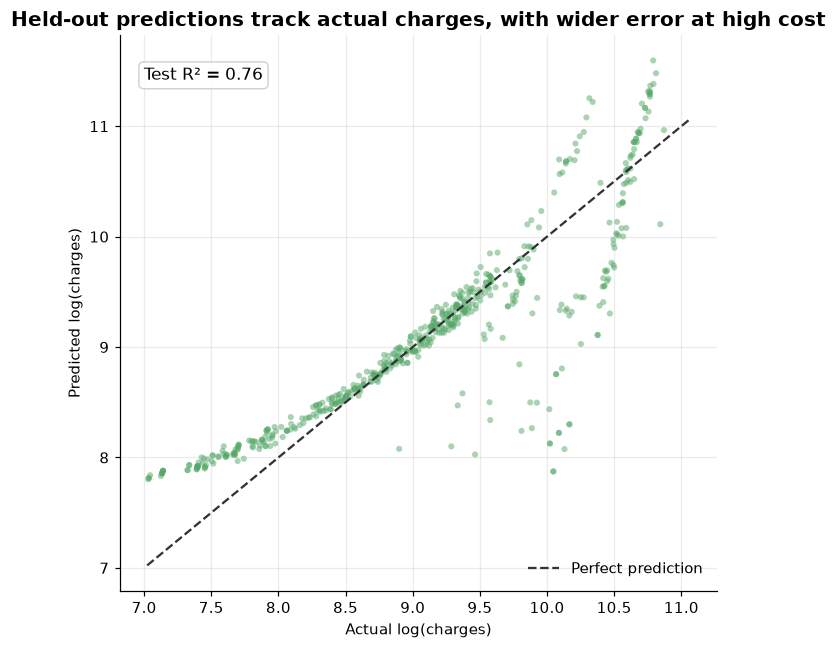

In [13]:
train_beta = fit_ols(design[train_idx], y[train_idx])
test_pred = design[test_idx] @ train_beta

fig, ax = plt.subplots(figsize=(6.2, 6))
ax.scatter(y[test_idx], test_pred, s=16, alpha=0.5, color="#55A868", edgecolors="none")
limits = [y.min(), y.max()]
ax.plot(limits, limits, color="#333333", lw=1.5, ls="--", label="Perfect prediction")
ax.set_title("Held-out predictions track actual charges, with wider error at high cost")
ax.set_xlabel("Actual log(charges)")
ax.set_ylabel("Predicted log(charges)")
ax.text(
    0.04, 0.92, f"Test R² = {r_squared(y[test_idx], test_pred):.2f}",
    transform=ax.transAxes, fontsize=11,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="#cccccc"),
)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(FIG_DIR / "predicted_vs_actual.png", bbox_inches="tight")
plt.show()

## 8. Key findings

1. **Smoking is the dominant factor.** The median smoker's annual charges are
   4.7 times the median non-smoker's, and the gap persists in every age band.
2. **BMI is only expensive for smokers.** Charges rise by roughly \$1,470 per BMI
   point for smokers but by only \$76 for non-smokers; the correlation with BMI is
   0.81 versus 0.08. This interaction, not BMI alone, is what the model captures.
3. **Age raises cost for both groups**, by about 3.5% per year, but it never closes
   the smoking gap.
4. **Region and number of children are weak predictors**, with no monotone pattern
   in either group medians or model coefficients.
5. **A compact log-linear model generalises well**: six predictors plus one
   interaction reach a held-out R² of about 0.76.

## 9. Limitations

- The data are observational and cross-sectional, so the associations are not
  causal. A smoker's higher charges may partly reflect unmeasured health status.
- The dataset is a teaching extract with no information on plan type, chronic
  conditions, income or geography beyond four coarse US regions. Charges also
  reflect a single historical price level, so the dollar amounts are not current.
- Eleven records (0.4%) with missing age or smoking status were dropped; a
  sensitivity analysis imputing them would be the natural next step.
- The model is deliberately simple. A gradient-boosted model and a proper
  cross-validation loop would give a more reliable estimate of out-of-sample error.
- The predicted-versus-actual plot compresses the tail: the most expensive policies
  (log charges above about 10) are systematically under-predicted, so the model is
  least trustworthy exactly where the financial risk is highest.

## 10. Reproducing the analysis

From the repository root:

```bash
pip install -r requirements.txt
jupyter lab notebooks/insurance_cost_analysis.ipynb
```

Run all cells; the cleaned dataset is written to `data/medical_insurance_clean.csv`
and the figures to `figures/`.